### Vaidya_alpha_dependency.ipynb

Ruud van Witzenburg

# Summary: 

This code is based on the Jupyter Notebook tutorials on MOTSfinder in [3]. We look at the dependency of the shear of the outgoing null normal vector to the slicing parameter. 

# Other Notes:
- MOTSFinder assumes axisymmetry; each 2D plot drawn is the $xz$ plane



### References: 

[3] D. Pook-Kolb, O. Birnholtz, B. Krishnan and E. Schnetter "Existence and stability of marginally trapped surfaces in black-hole spacetimes." Physical Review D 99.6 (2019): 064005.

In [1]:
%matplotlib inline
import sys
import os

# Change the path to where the code is located.
sys.path.append(os.path.expanduser('~/src/distorted-motsfinder-public')) 

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from numpy.random import normal, seed
import spinsfast
import matplotlib.cm as cm
from scipy.interpolate import interp1d
import spinsfast
from motsfinder.ipyutils import reload_all
from motsfinder.utils import save_to_file, load_from_file
import pandas as pd

exec(reload_all())

# Defining Mass Function

In [2]:
def M(coordx, coordy, coordz, order=0, param=0):
    """
    Mass function and its derivatives

    coordx    : Int, x-coordinate of the induced metric
    coordy    : Int, y-coordinate of the induced metric
    coordz    : Int, z-coordinate of the induced metric
    order     : Int, order of derivative
    param     : Int, parameter used in derivative [0,1,2,3] = [t,x,y,z]
    """
        
    r = np.sqrt(coordx**2 + coordy**2 + coordz**2)
    v = t + f(coordz) + r          # t is τ (funky slicing time)

    if v <= 0:
        return 0

    dMdv = 2 * M0 * W**2 * v / (v**2 + W**2)**2

    if order == 0:
        return M0 * v**2 / (v**2 + W**2)
    elif order == 1:
        if param == 0:
            return dMdv              # ∂v/∂t_KS = 1
        elif param == 1:
            return dMdv * coordx/r   # ∂v/∂x = x/r
        elif param == 2:
            return dMdv * coordy/r   # ∂v/∂y = y/r
        elif param == 3:
            return dMdv * (coordz/r)
    else:
        raise NotImplementedError

#Slicing function and its derivatives.
f = lambda z: a*z            
fp = lambda z : a
fpp = lambda z : 0

# Creating the Funky Vaidya Slice 

In [3]:
#Constants
res = 200 # The inverse finite difference step size for taking derivatives
avalues = np.linspace(0,10/11,10)
#avalues = np.array([10/11])
#avalues = np.insert(avalues, 0, 0, axis=0)
W = 100
M0 = 1.0
tlist = np.array([200])
#tlist = np.array([4000000])
AH_list = []

### Discretize the metric ###
for j in range(len(avalues)):
    print('Progress: ', j/len(avalues)*100,'%')
    a = avalues[j]
    #print('a = ',a)
    for i in range(len(tlist)):
    # Creating the discretized metric, g, for the Vaidya slice, gV
        t = tlist[i]
        #print('t = ' + str(t))
        gV = VaidyaSliceFunky(fp,fpp, M)
        g = FDDerivMetric(
            metric = gV, # metric to discretize
            res = res, # resolution of finite difference method
            fd_order = 6 # order of the finite difference method
        )

        r_plus = 2 * M0
        initial_guess = StarShapedCurve.create_sphere(
            radius = r_plus,
            origin = (0,0,0)
        )

        c_AH = find_mots(
            cfg = GeneralMotsConfig.preset(
                'discrete8', 
                metric = g, 
                hname = 'AH', 
                num = 50, 
                atol = 1e-12,
                reparam = False,
                c_ref = initial_guess, 
                verbose = False,
                plot_steps = False,
            ),
            steps=50,
        )
        AH_list.append(c_AH)
print('Done!')

Progress:  0.0 %
Progress:  10.0 %
Progress:  20.0 %
Progress:  30.0 %
Progress:  40.0 %
Progress:  50.0 %
Progress:  60.0 %
Progress:  70.0 %
Progress:  80.0 %
Progress:  90.0 %
Done!


In [4]:
# Parameters for the Schwarzschild metrice below); note this is the radial coordinate of the event horizon
r_plus_schw = 2*M0
AH_list_schwarzschild = []

### Discretize the metric ###
for i in range(len(avalues)):
    # Creating the discretized metric, g, for the Schwarzschild slice, gKS
    a = avalues[i]
    print(a)
    gKS = SchwarzschildKSSliceFunky(fp,fpp, M = M0)
    g = FDDerivMetric(
        metric = gKS, # metric to discretize
        res = res, # resolution of finite difference method
        fd_order = 6 # order of the finite difference method
    )
    
    schw_AH = find_mots(
        cfg = GeneralMotsConfig.preset(
            'discrete8', 
            metric = g, 
            hname = 'AH', 
            num = 30, 
            atol = 1e-12,
            reparam = False,
            c_ref = r_plus_schw, # Note: depending on your choice of c_ref, a MOTS can be easily or not as easily found.
                            # In the latter case, refine your reference shape.
            verbose = True,
            plot_steps = False,
        )
    
    )
    AH_list_schwarzschild.append(schw_AH)

0.0
01: max error at 30 collocation points: 5.956346527113965e-14
  Accurate error = 4.63518e-14 <= 1e-12 at resolution 30
0.10101010101010101
01: max error at 30 collocation points: 4.879430193227563e-14
  Accurate error = 6.75571e-14 <= 1e-12 at resolution 30
0.20202020202020202
01: max error at 30 collocation points: 5.762057497804562e-14
  Accurate error = 5.13478e-14 <= 1e-12 at resolution 30
0.30303030303030304
01: max error at 30 collocation points: 6.161737786669619e-14
  Accurate error = 5.44009e-14 <= 1e-12 at resolution 30
0.40404040404040403
01: max error at 30 collocation points: 4.1799896877137144e-14
  Accurate error = 4.86278e-14 <= 1e-12 at resolution 30
0.5050505050505051
01: max error at 30 collocation points: 4.7628567756419216e-14
  Accurate error = 5.22915e-14 <= 1e-12 at resolution 30
0.6060606060606061
01: max error at 30 collocation points: 6.017408793468348e-14
  Accurate error = 5.54001e-14 <= 1e-12 at resolution 30
0.7070707070707071
01: max error at 30 coll

# Creating parametrized table of shear and expansion for Vaidya

In [5]:
Nt = len(tlist)
Na = len(avalues)
lalist = np.linspace(0.01, np.pi, 100)

data = {j: {i: {'expansion k': [], 'shear k': [], 'shear l': []}
             for i in range(Nt)}
        for j in range(Na)}

for la in lalist:
    for j in range(Na):
        a = avalues[j]      
        for i in range(Nt):
            t = tlist[i]
            ah   = AH_list[j * Nt + i]
            calc = ah.get_stability_calc_obj(la)
            shear_k, shear_squared, expansion_k, shear_k_trace = \
                calc.compute_shear_k(full_output=True)
            data[j][i]['shear k'].append(complex(np.asarray(shear_k).flat[0])) 
            data[j][i]['expansion k'].append(np.real(expansion_k))
            data[j][i]['shear l'].append(ah.shear_scalar(la))
    print("Done with", round(la / np.pi * 100, 1), '%')
print('Done!')


Done with 0.3 %
Done with 1.3 %
Done with 2.3 %
Done with 3.3 %
Done with 4.3 %
Done with 5.4 %
Done with 6.4 %
Done with 7.4 %
Done with 8.4 %
Done with 9.4 %
Done with 10.4 %
Done with 11.4 %
Done with 12.4 %
Done with 13.4 %
Done with 14.4 %
Done with 15.4 %
Done with 16.4 %
Done with 17.4 %
Done with 18.4 %
Done with 19.4 %
Done with 20.5 %
Done with 21.5 %
Done with 22.5 %
Done with 23.5 %
Done with 24.5 %
Done with 25.5 %
Done with 26.5 %
Done with 27.5 %
Done with 28.5 %
Done with 29.5 %
Done with 30.5 %
Done with 31.5 %
Done with 32.5 %
Done with 33.5 %
Done with 34.6 %
Done with 35.6 %
Done with 36.6 %
Done with 37.6 %
Done with 38.6 %
Done with 39.6 %
Done with 40.6 %
Done with 41.6 %
Done with 42.6 %
Done with 43.6 %
Done with 44.6 %
Done with 45.6 %
Done with 46.6 %
Done with 47.6 %
Done with 48.6 %
Done with 49.7 %
Done with 50.7 %
Done with 51.7 %
Done with 52.7 %
Done with 53.7 %
Done with 54.7 %
Done with 55.7 %
Done with 56.7 %
Done with 57.7 %
Done with 58.7 %
Done wi

In [6]:
schw_data = {j: {'expansion k': [], 'shear k': [], 'shear l': []}
             for j in range(Na)}

for la in lalist:
    for j in range(Na):
        a = avalues[j]   
        ah   = AH_list_schwarzschild[j]
        calc = ah.get_stability_calc_obj(la)
        shear_k, shear_squared, expansion_k, shear_k_trace = \
            calc.compute_shear_k(full_output=True)
        schw_data[j]['shear k'].append(complex(np.asarray(shear_k).flat[0])) 
        schw_data[j]['expansion k'].append(np.real(expansion_k))
        schw_data[j]['shear l'].append(ah.shear_scalar(la))

# Plotting Spherical Harmonics

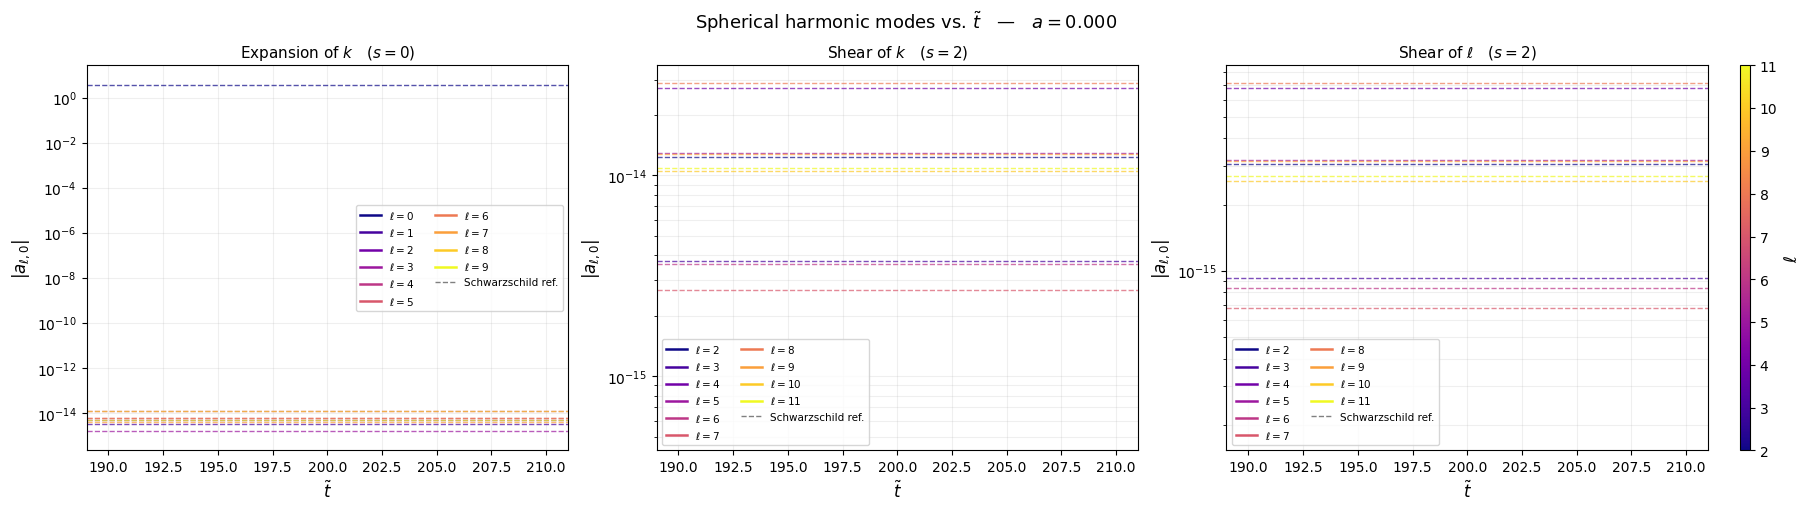

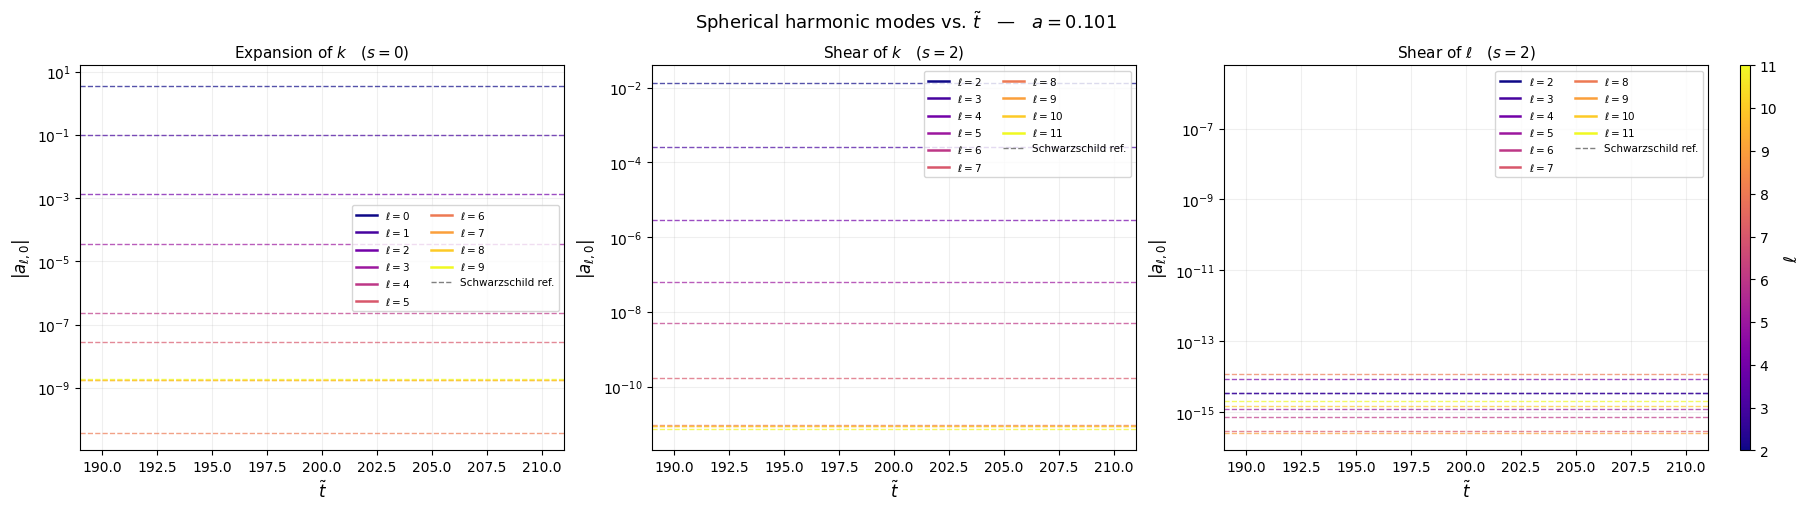

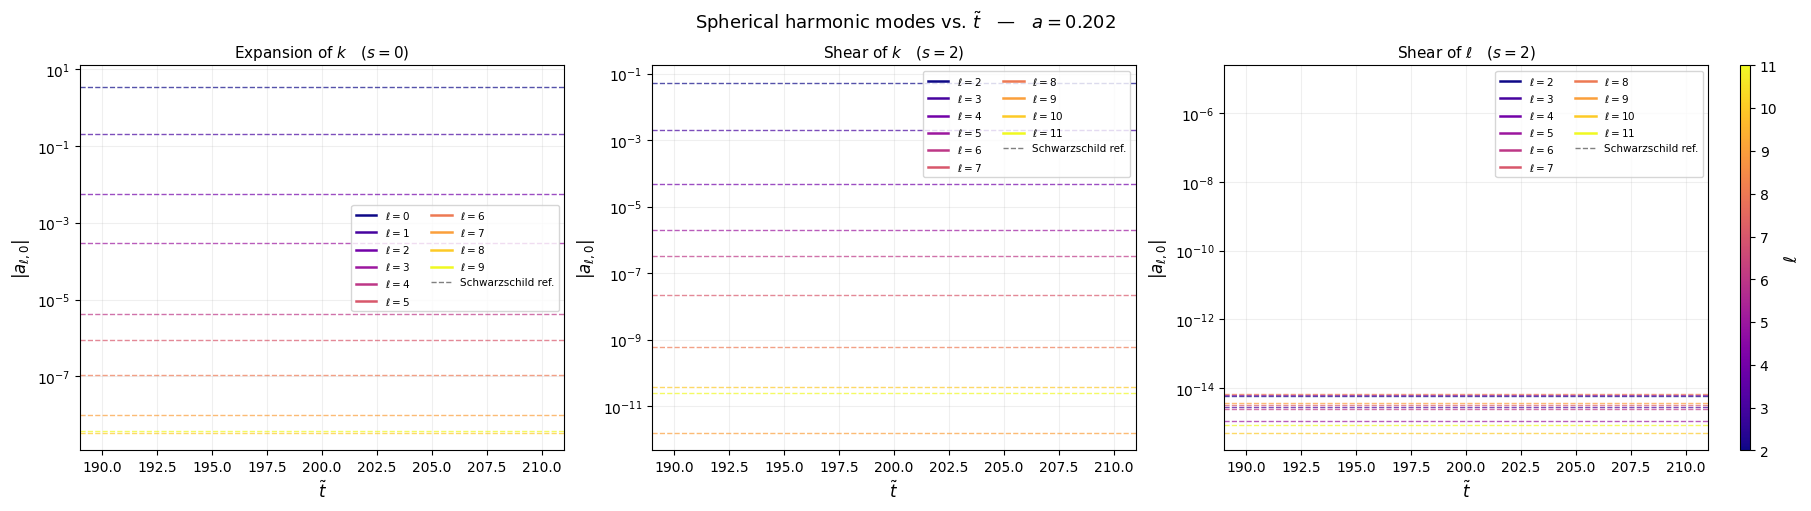

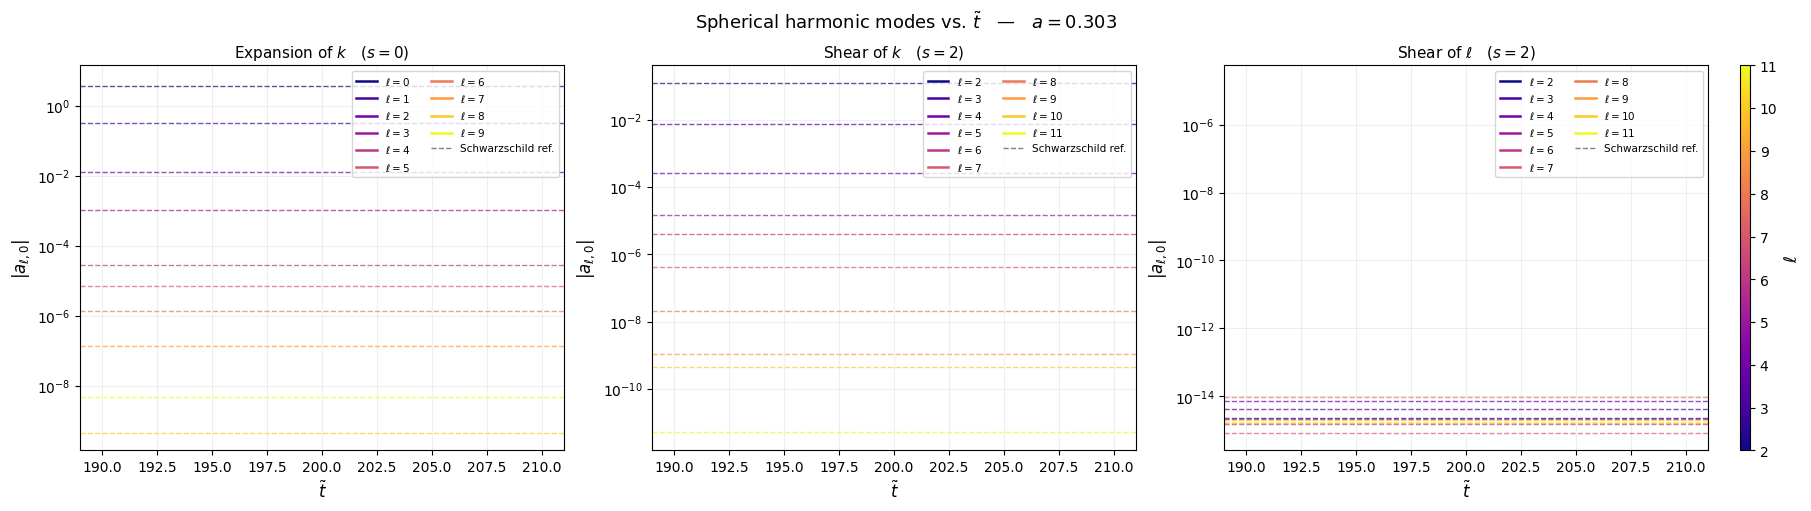

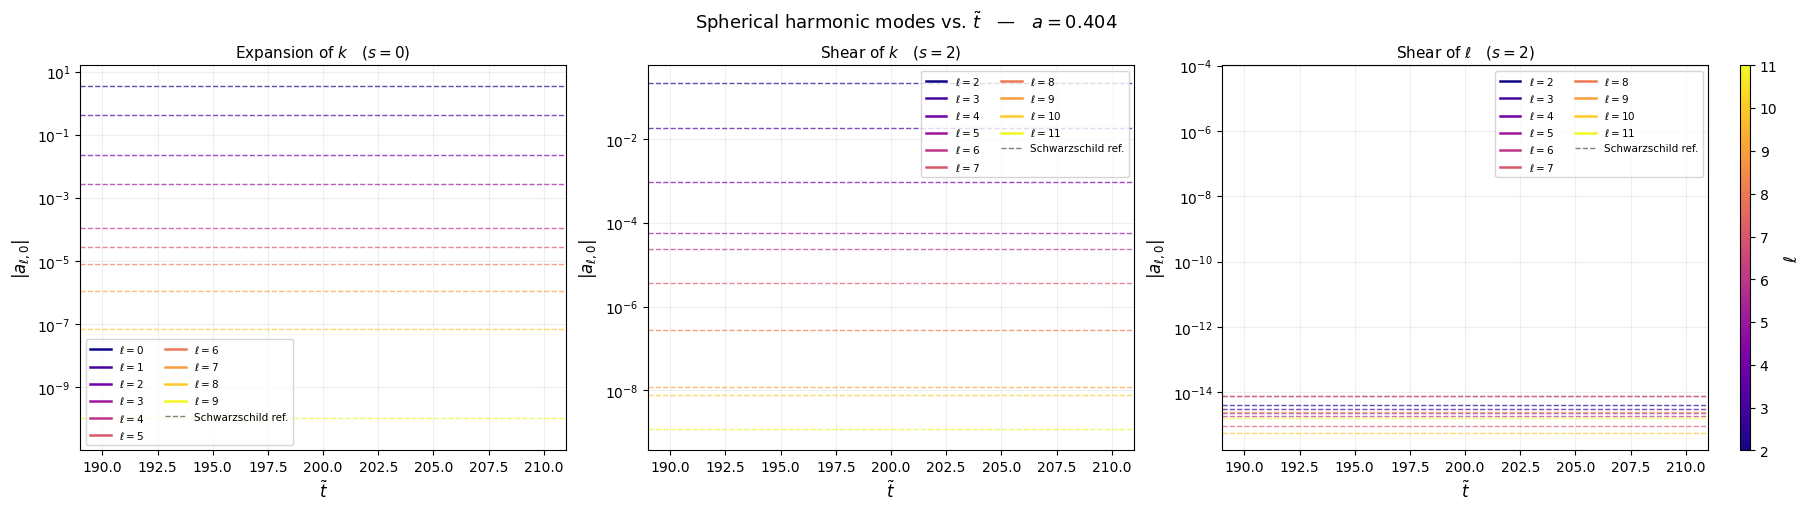

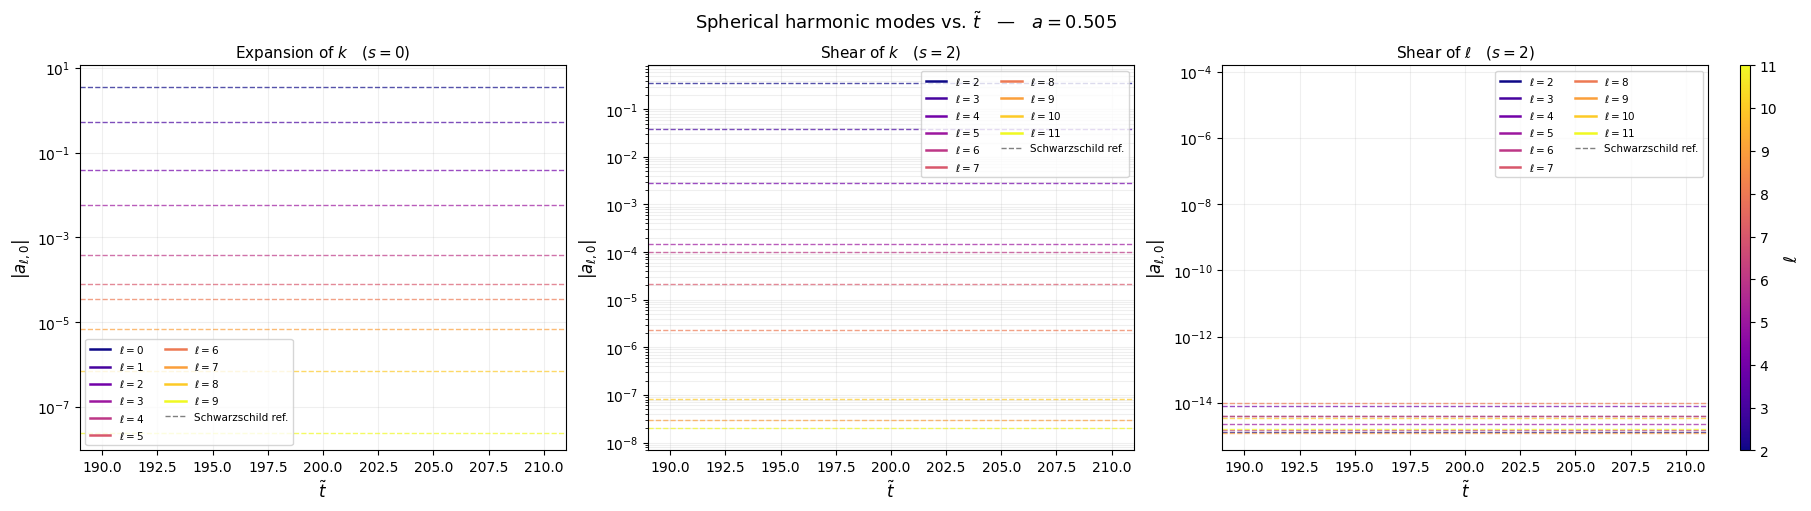

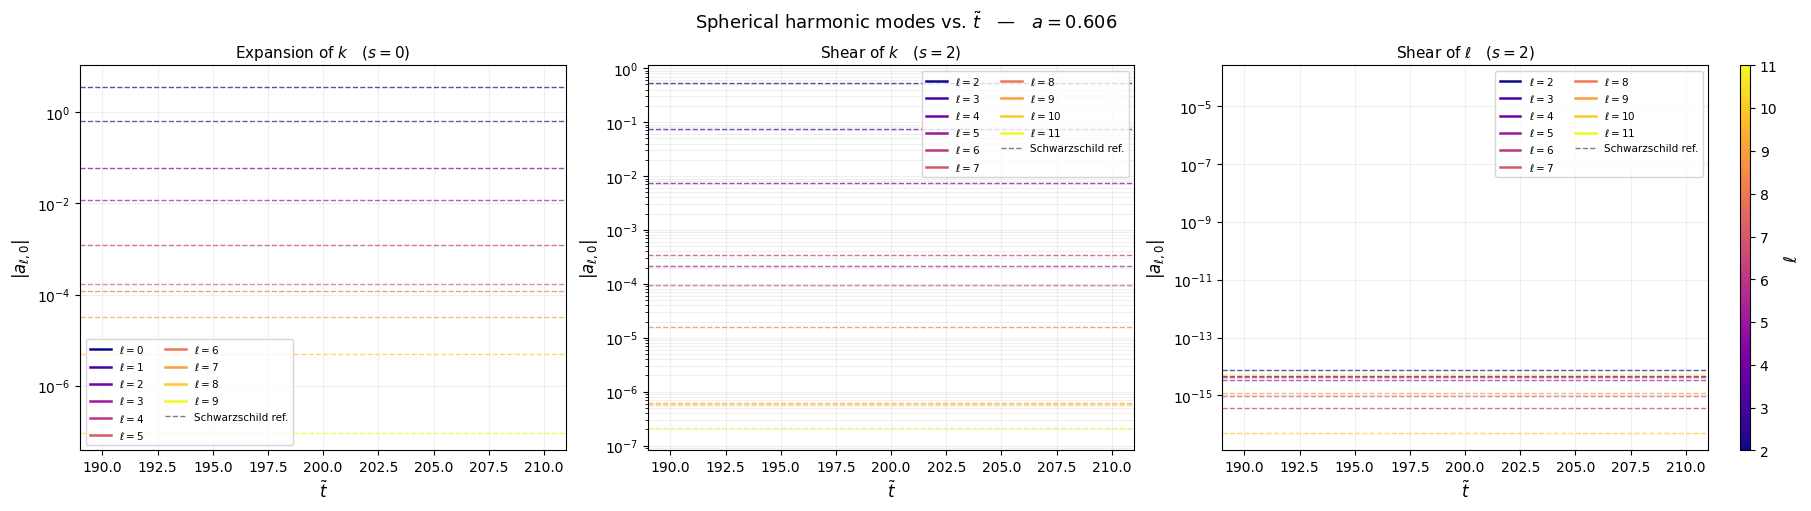

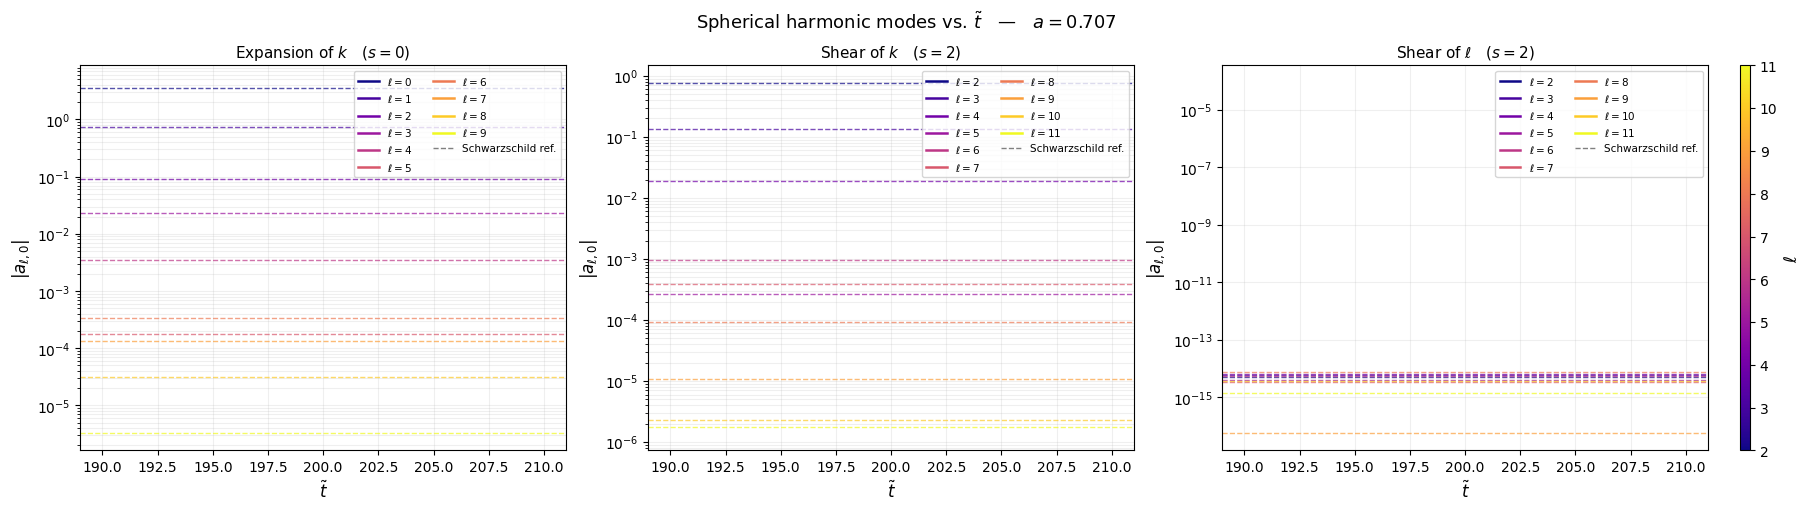

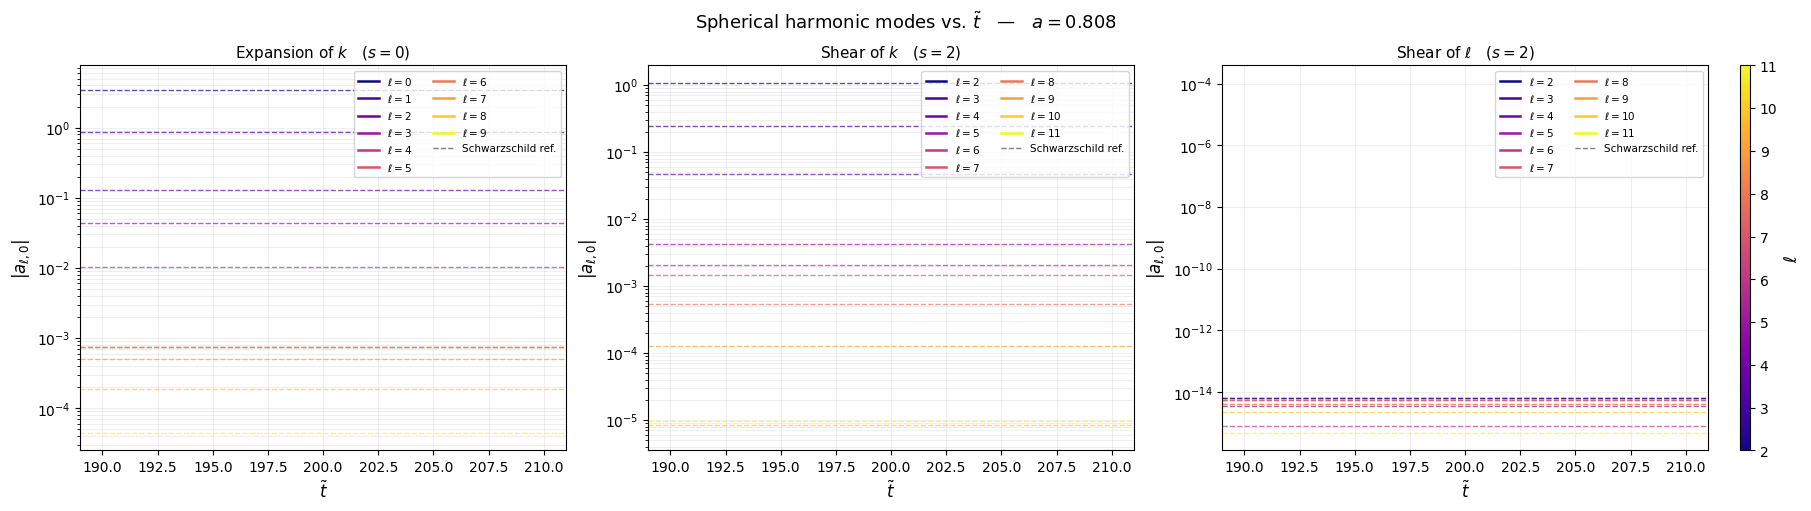

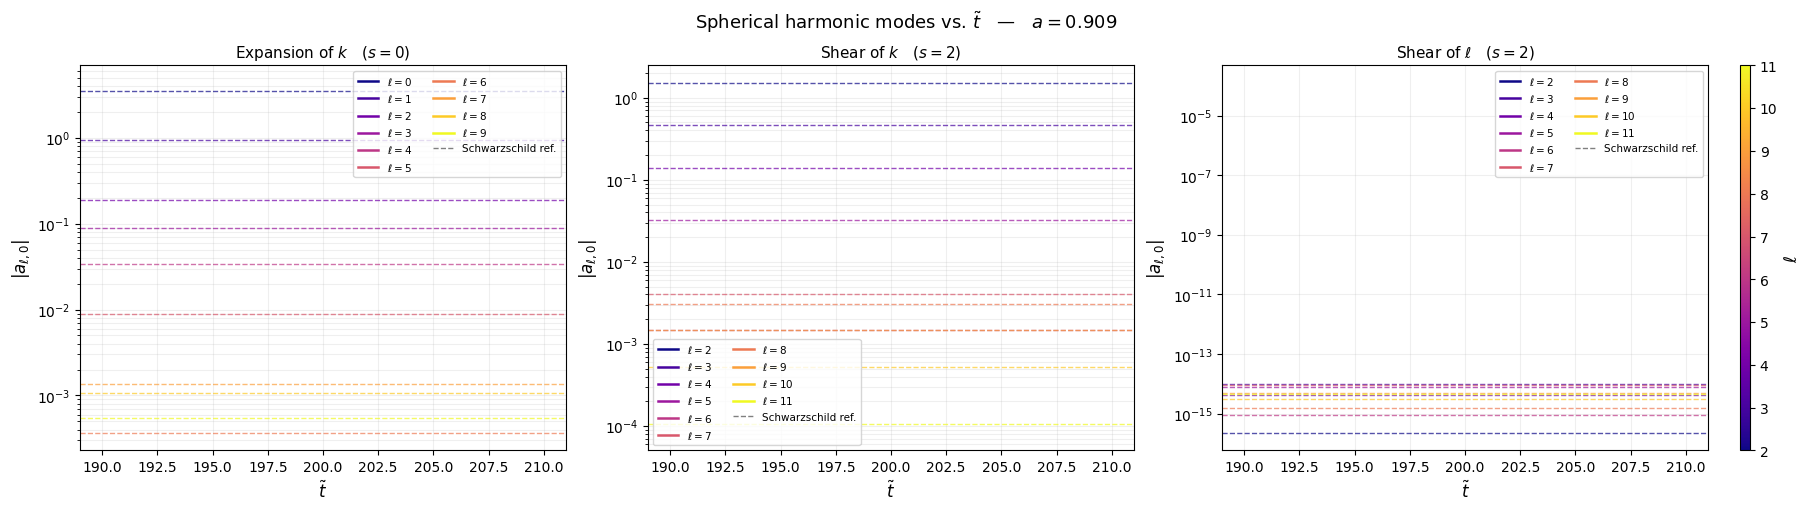

In [7]:
# ── Grid ──────────────────────────────────────────────────────────────────────
N_MODES = 10
LMAX    = 49
Ntheta  = 2*LMAX + 1
Nphi    = 2*LMAX + 1

theta_grid = np.linspace(0.0, np.pi, Ntheta, endpoint=True)
lm_pairs = [(ell, m) for ell in range(LMAX+1) for m in range(-ell, ell+1)]

def build_axisym_map(theta_src, f_src, theta_dst, Nphi):
    """Interpolate a complex 1-D axisymmetric field onto the spinsfast grid."""
    re = interp1d(theta_src, np.real(f_src), kind='cubic', axis=0,
                  bounds_error=False, fill_value=(np.real(f_src[0]), np.real(f_src[-1])))
    im = interp1d(theta_src, np.imag(f_src), kind='cubic', axis=0,
                  bounds_error=False, fill_value=(np.imag(f_src[0]), np.imag(f_src[-1])))
    f_interp = re(theta_dst) + 1j * im(theta_dst)
    return np.tile(f_interp[:, None], (1, Nphi))

def compute_alm_row(f_data, spin):
    """Return |a_{ell,0}| coefficients.  spin=0 for expansion, spin=2 for shears."""
    sph_map = build_axisym_map(lalist, np.asarray(f_data), theta_grid, Nphi)
    alm     = spinsfast.map2salm(sph_map, spin, LMAX)   # ← spin=2 for shears
    return np.array([abs(alm[k]) for k, (ell, m) in enumerate(lm_pairs) if m == 0])

# spin weight for each quantity
SPIN = {'expansion k': 0, 'shear k': 2, 'shear l': 2}

t_arr = np.asarray(tlist)

quantities = [
    ('expansion k', r'Expansion of $k \quad (s=0)$'),
    ('shear k',     r'Shear of $k \quad (s=2)$'),
    ('shear l',     r'Shear of $\ell \quad (s=2)$'),
]

# ── Vaidya alm: alm_data[j][qty_key] shape (Nt, LMAX+1) ─────────────────────
alm_data = {}
for j in range(Na):
    alm_data[j] = {}
    for qty_key, _ in quantities:
        spin = SPIN[qty_key]
        mat  = [compute_alm_row(data[j][i][qty_key], spin) for i in range(Nt)]
        alm_data[j][qty_key] = np.array(mat)

# ── Schwarzschild reference alm ───────────────────────────────────────────────
schw_alm = {}
for j in range(Na):
    schw_alm[j] = {}
    for qty_key, _ in quantities:
        spin = SPIN[qty_key]
        schw_alm[j][qty_key] = compute_alm_row(schw_data[j][qty_key], spin)


# ── Colour scheme ─────────────────────────────────────────────────────────────
_cmap = cm.plasma
_norm = mcolors.Normalize(vmin=0, vmax=N_MODES - 1)
def mode_color(ell): return _cmap(_norm(ell))

# ── Plots ─────────────────────────────────────────────────────────────────────
SPIN_LMIN = {'expansion k': 0, 'shear k': 2, 'shear l': 2}

for j in range(Na):
    a_val = avalues[j]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
    fig.suptitle(
        rf'Spherical harmonic modes vs. $\tilde{{t}}$   —   $a = {a_val:.3f}$',
        fontsize=13
    )

    for ax, (qty_key, qty_title) in zip(axes, quantities):
        vaidya_mat = alm_data[j][qty_key]
        schw_vec   = schw_alm[j][qty_key]
        lmin       = SPIN_LMIN[qty_key]

        ell_range  = range(lmin, lmin + N_MODES)
        local_norm = mcolors.Normalize(vmin=lmin, vmax=lmin + N_MODES - 1)

        for k, ell in enumerate(ell_range):
            c = _cmap(local_norm(ell))

            ax.plot(t_arr, vaidya_mat[:, ell],
                    color=c, linewidth=1.8,
                    label=rf'$\ell={ell}$')

            ref = schw_vec[ell]
            if ref > 0:
                ax.axhline(ref, color=c, linewidth=1.0, linestyle='--', alpha=0.7)

        ax.set_xlabel(r'$\tilde{t}$', fontsize=12)
        ax.set_ylabel(r'$|a_{\ell,0}|$', fontsize=12)
        ax.set_title(qty_title, fontsize=11)
        ax.set_yscale('log')
        ax.grid(True, which='both', alpha=0.2)

        handles, labels = ax.get_legend_handles_labels()
        ref_line = Line2D([0], [0], color='grey', linewidth=1.0,
                          linestyle='--', label='Schwarzschild ref.')
        ax.legend(handles=handles + [ref_line],
                  labels=labels  + ['Schwarzschild ref.'],
                  fontsize=7.5, ncol=2)

    sm = cm.ScalarMappable(cmap=_cmap, norm=mcolors.Normalize(
        vmin=SPIN_LMIN['shear k'], vmax=SPIN_LMIN['shear k'] + N_MODES - 1))
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes, orientation='vertical',
                        fraction=0.015, pad=0.02, aspect=40)
    cbar.set_label(r'$\ell$', fontsize=12)
    cbar.set_ticks(range(SPIN_LMIN['shear k'], SPIN_LMIN['shear k'] + N_MODES))

    plt.show()


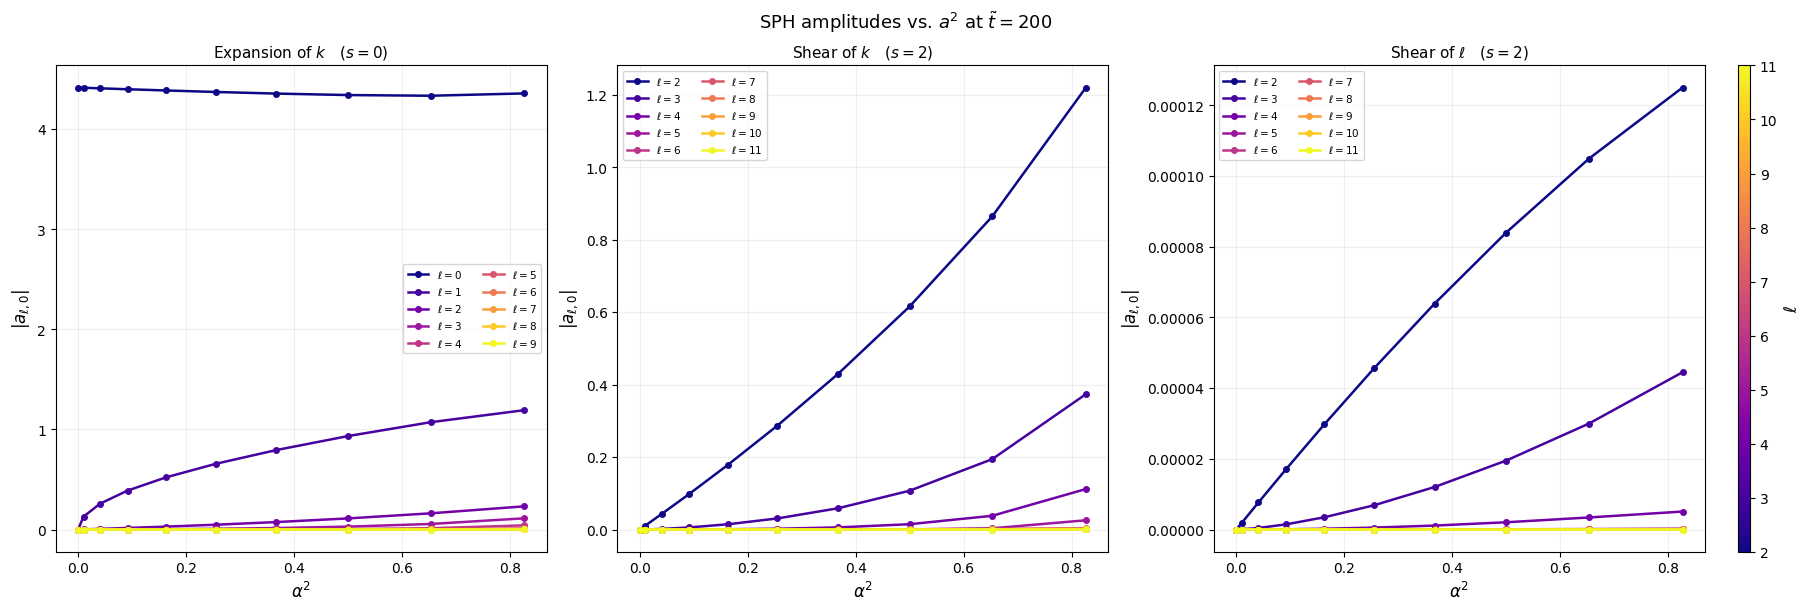

Saved → sph_vs_asq_t200.png


In [10]:
t=tlist[0]
i_t = int(np.argmin(t))

a_arr = np.asarray(avalues)
a_sq  = a_arr**2

alm_vs_a = {}
for qty_key, _ in quantities:
    alm_vs_a[qty_key] = np.array(
        [compute_alm_row(data[j][i_t][qty_key], SPIN[qty_key]) for j in range(Na)]
    )

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
fig.suptitle(
    rf'SPH amplitudes vs. $a^2$ at $\tilde{{t}} = {t:.0f}$',
    fontsize=13
)

for ax, (qty_key, qty_title) in zip(axes, quantities):
    lmin       = SPIN_LMIN[qty_key]
    local_norm = mcolors.Normalize(vmin=lmin, vmax=lmin + N_MODES - 1)
    mat        = alm_vs_a[qty_key]

    for ell in range(lmin, lmin + N_MODES):
        c = _cmap(local_norm(ell))
        ax.plot(a_sq, mat[:, ell], color=c, linewidth=1.8,
                marker='o', ms=4, label=rf'$\ell={ell}$')

    ax.set_xlabel(r'$\alpha^2$', fontsize=12)
    ax.set_ylabel(r'$|a_{\ell,0}|$', fontsize=12)
    ax.set_title(qty_title, fontsize=11)
    ax.grid(True, which='both', alpha=0.2)
    ax.legend(fontsize=7.5, ncol=2)

sm = cm.ScalarMappable(cmap=_cmap,
                        norm=mcolors.Normalize(vmin=SPIN_LMIN['shear k'],
                                               vmax=SPIN_LMIN['shear k'] + N_MODES - 1))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, orientation='vertical',
                    fraction=0.015, pad=0.02, aspect=40)
cbar.set_label(r'$\ell$', fontsize=12)
cbar.set_ticks(range(SPIN_LMIN['shear k'], SPIN_LMIN['shear k'] + N_MODES))

fname = f'sph_vs_asq_t{t:.0f}.png'
plt.savefig(fname, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fname}")